--- Cleaned State Dataset (First 5 Rows) ---
metric                     Clean_Fuel  Health_Insurance  High_Blood_Sugar  \
state                                                                       
Andaman & Nicobar Islands        79.8               1.6             17.70   
Andhra Pradesh                   83.6              70.2             20.65   
Arunachal Pradesh                53.2              29.3             10.15   
Assam                            42.1              60.0             14.40   
Bihar                            37.8              14.6             14.45   

metric                     Hypertension  Improved_Sanitation  
state                                                         
Andaman & Nicobar Islands     17.133333                 88.0  
Andhra Pradesh                16.416667                 77.3  
Arunachal Pradesh             18.816667                 82.9  
Assam                         12.083333                 68.6  
Bihar                         10.3500

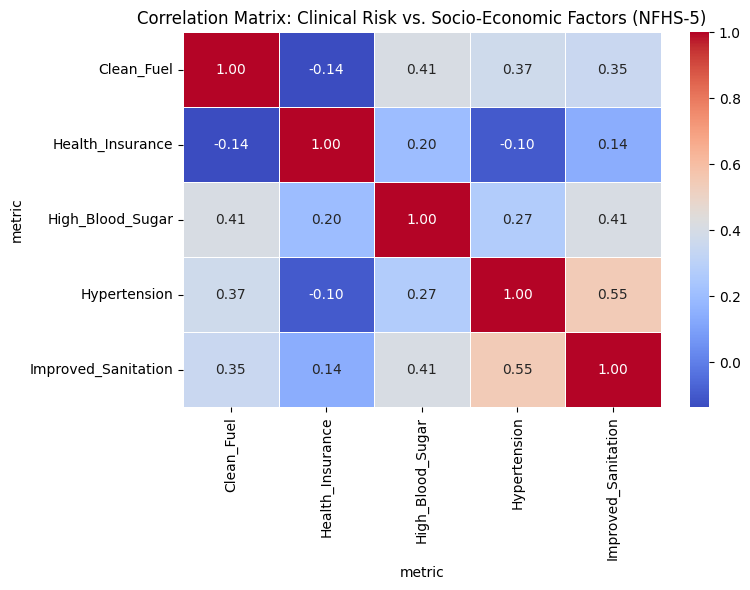

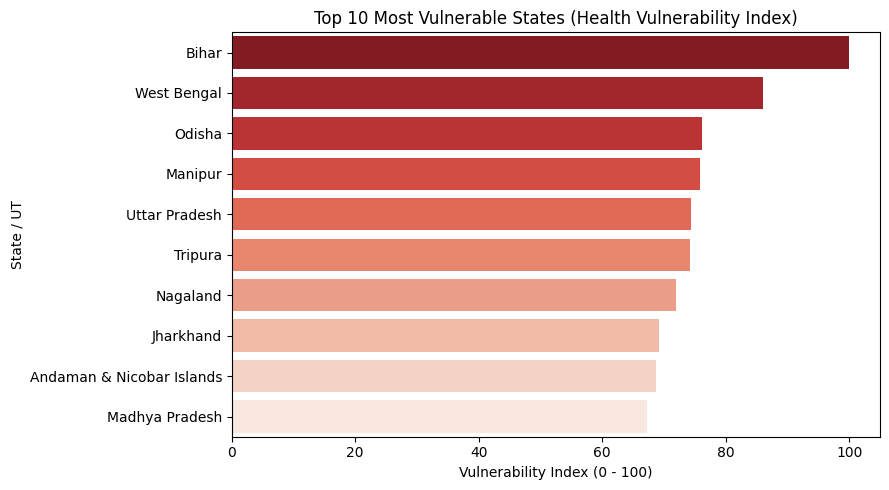


--- Top 10 Most Vulnerable States ---
metric                     High_Blood_Sugar  Hypertension  Health_Insurance  \
state                                                                         
Bihar                                 14.45         10.35              14.6   
West Bengal                           19.40         12.45              29.3   
Odisha                                15.50         14.90              47.9   
Manipur                               15.05         17.63              14.2   
Uttar Pradesh                         10.80         12.82              15.9   
Tripura                               18.50         13.03              33.0   
Nagaland                              10.85         16.75              20.5   
Jharkhand                             12.15         12.95              50.3   
Andaman & Nicobar Islands             17.70         17.13               1.6   
Madhya Pradesh                        11.00         13.83              38.1   

metric      

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load data & remove the overall "India" row so we only compare States/UTs
url = "https://raw.githubusercontent.com/pratapvardhan/NFHS-5/master/NFHS-5-States.csv"
df = pd.read_csv(url)
df = df[df['state'] != 'India'].copy()

# Ensure values are numeric
df['nfhs5_total'] = pd.to_numeric(df['nfhs5_total'], errors='coerce')

# 2. Pick 5 core indicators (Clinical + Socio-Economic)
def label_indicator(text):
    t = str(text).lower()
    if 'blood sugar level - high or very high' in t:
        return 'High_Blood_Sugar'
    elif 'elevated blood pressure' in t:
        return 'Hypertension'
    elif 'health insurance' in t:
        return 'Health_Insurance'
    elif 'clean fuel for cooking' in t:
        return 'Clean_Fuel'
    elif 'improved sanitation' in t:
        return 'Improved_Sanitation'
    return None

df['metric'] = df['indicator'].apply(label_indicator)
filtered = df.dropna(subset=['metric'])

# 3. Pivot into a clean table (1 row per State, 5 columns)
# Averages Men & Women rows automatically for adult population metrics
pivot_df = filtered.groupby(['state', 'metric'])['nfhs5_total'].mean().unstack().dropna()

print("--- Cleaned State Dataset (First 5 Rows) ---")
print(pivot_df.head())

# 4. CORRELATION MATRIX & HEATMAP (For Slide 4)
corr = pivot_df.corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix: Clinical Risk vs. Socio-Economic Factors (NFHS-5)")
plt.tight_layout()
plt.savefig("heatmap.png", dpi=300)
plt.show()

# 5. CALCULATE VULNERABILITY INDEX (0 to 100)
# Clinical risks ADD to vulnerability; Socio-economic protections SUBTRACT from it
raw_score = (
    (pivot_df['High_Blood_Sugar'] * 0.30) +
    (pivot_df['Hypertension'] * 0.30) -
    (pivot_df['Health_Insurance'] * 0.15) -
    (pivot_df['Clean_Fuel'] * 0.15) -
    (pivot_df['Improved_Sanitation'] * 0.10)
)

pivot_df['Vulnerability_Index'] = ((raw_score - raw_score.min()) / (raw_score.max() - raw_score.min())) * 100
pivot_df = pivot_df.sort_values(by='Vulnerability_Index', ascending=False)

# 6. TOP 10 MOST VULNERABLE STATES CHART (For Slide 5)
top10 = pivot_df.head(10)
plt.figure(figsize=(9, 5))
sns.barplot(x=top10['Vulnerability_Index'], y=top10.index, hue=top10.index, palette='Reds_r', legend=False)
plt.title("Top 10 Most Vulnerable States (Health Vulnerability Index)")
plt.xlabel("Vulnerability Index (0 - 100)")
plt.ylabel("State / UT")
plt.tight_layout()
plt.savefig("top10_states.png", dpi=300)
plt.show()

print("\n--- Top 10 Most Vulnerable States ---")
print(pivot_df[['High_Blood_Sugar', 'Hypertension', 'Health_Insurance', 'Vulnerability_Index']].head(10).round(2))